# Procesamiento de lenguaje natural: detección de sarcasmo en titulares
**Minería de Datos I — ISTEA (Clase 11)** · Prof. Kevin Kovacs

**Objetivo:** clasificar titulares de noticias como sarcásticos o no a partir de su texto.
**Datos:** [News Headlines Dataset for Sarcasm Detection](https://www.kaggle.com/datasets/rmisra/news-headlines-dataset-for-sarcasm-detection) (Kaggle), 28.619 titulares.
**Qué hice:** limpié el texto (minúsculas, sin signos ni stopwords), apliqué stemming y lematización, convertí los titulares en una bolsa de palabras con CountVectorizer (1.000 palabras) y comparé tres modelos.
**Resultado principal:** la regresión logística alcanza 73,0% de accuracy, contra 71,2% del Random Forest visto en clase.
**Qué aprendí:** a convertir texto en números para un modelo y la diferencia entre stemming y lematización.

*Notebook desarrollado durante la cursada de Minería de Datos I (ISTEA).*

## Datos
Este notebook usa el archivo **`Sarcasm_Headlines_Dataset.json`**, del dataset [News Headlines Dataset for Sarcasm Detection (Kaggle)](https://www.kaggle.com/datasets/rmisra/news-headlines-dataset-for-sarcasm-detection).
Para ejecutarlo en Colab, descargá el archivo y subilo a la sesión (ícono de carpeta a la izquierda) antes de correr las celdas.

# Intro

In [1]:
texto = "Esto!!!!!! 1 es un hashtag###########"

In [2]:
import re
import pandas as pd

In [3]:
re.sub('[^a-zA-Z]','', texto)

'Estoesunhashtag'

In [4]:
from sklearn.feature_extraction.text import CountVectorizer

In [5]:
s1 = "me gustan los perros"

In [6]:
s2 = "hay perros y perros"

In [7]:
s3 = "hay muchas razas de perros"

In [8]:
corpus = [s1, s2, s3]

In [9]:
corpus

['me gustan los perros', 'hay perros y perros', 'hay muchas razas de perros']

In [10]:
vec = CountVectorizer()

In [11]:
X = vec.fit_transform(corpus)

In [12]:
X

<Compressed Sparse Row sparse matrix of dtype 'int64'
	with 11 stored elements and shape (3, 8)>

In [13]:
X.toarray()

array([[0, 1, 0, 1, 1, 0, 1, 0],
       [0, 0, 1, 0, 0, 0, 2, 0],
       [1, 0, 1, 0, 0, 1, 1, 1]])

In [14]:
vec.get_feature_names_out()

array(['de', 'gustan', 'hay', 'los', 'me', 'muchas', 'perros', 'razas'],
      dtype=object)

In [15]:
matrix = pd.DataFrame(X.toarray(), columns=vec.get_feature_names_out())

In [16]:
matrix

,de,gustan,hay,los,me,muchas,perros,razas
0,0,1,0,1,1,0,1,0
1,0,0,1,0,0,0,2,0
2,1,0,1,0,0,1,1,1


In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [18]:
import nltk

In [19]:
nltk.download('stopwords')

In [20]:
nltk.download('punkt')
nltk.download('punkt_tab')

In [21]:
df = pd.read_json('Sarcasm_Headlines_Dataset.json', lines = True)

In [22]:
df

,is_sarcastic,headline,article_link
0,1,thirtysomething scientists unveil doomsday clo...,https://www.theonion.com/thirtysomething-scien...
1,0,dem rep. totally nails why congress is falling...,https://www.huffingtonpost.com/entry/donna-edw...
2,0,eat your veggies: 9 deliciously different recipes,https://www.huffingtonpost.com/entry/eat-your-...
3,1,inclement weather prevents liar from getting t...,https://local.theonion.com/inclement-weather-p...
4,1,mother comes pretty close to using word 'strea...,https://www.theonion.com/mother-comes-pretty-c...
...,...,...,...
28614,1,jews to celebrate rosh hashasha or something,https://www.theonion.com/jews-to-celebrate-ros...
28615,1,internal affairs investigator disappointed con...,https://local.theonion.com/internal-affairs-in...
28616,0,the most beautiful acceptance speech this week...,https://www.huffingtonpost.com/entry/andrew-ah...
28617,1,mars probe destroyed by orbiting spielberg-gat...,https://www.theonion.com/mars-probe-destroyed-...


In [23]:
df.shape

(28619, 3)

In [24]:
index_random = np.random.randint(0, df.shape[0])

In [25]:
index_random

17131

In [26]:
titular = df.iloc[index_random]

In [27]:
titular

is_sarcastic                                                    0
headline        obama says voting barriers are directly linked...
article_link    https://www.huffingtonpost.com/entry/obama-vot...
Name: 17131, dtype: object

In [28]:
type(titular.headline)

str

In [29]:
titular_st = nltk.sent_tokenize(titular.headline)

In [30]:
titular_st

['obama says voting barriers are directly linked to jim crow and slavery']

In [31]:
titular_word = nltk.word_tokenize(titular.headline)

In [32]:
stopwords = nltk.corpus.stopwords.words('english')

In [33]:
#stopwords = nltk.corpus.stopwords.words('spanish')

In [34]:
stopwords[:20]

['a',
 'about',
 'above',
 'after',
 'again',
 'against',
 'ain',
 'all',
 'am',
 'an',
 'and',
 'any',
 'are',
 'aren',
 "aren't",
 'as',
 'at',
 'be',
 'because',
 'been']

In [35]:
titular_word

['obama',
 'says',
 'voting',
 'barriers',
 'are',
 'directly',
 'linked',
 'to',
 'jim',
 'crow',
 'and',
 'slavery']

In [36]:
titular_sw = [word for word in titular_word if word not in stopwords]

In [37]:
titular_sw

['obama',
 'says',
 'voting',
 'barriers',
 'directly',
 'linked',
 'jim',
 'crow',
 'slavery']

In [38]:
freq = nltk.FreqDist(titular_sw)

In [39]:
freq

FreqDist({'obama': 1, 'says': 1, 'voting': 1, 'barriers': 1, 'directly': 1, 'linked': 1, 'jim': 1, 'crow': 1, 'slavery': 1})

# Analisis de DF no-sarcastico

In [40]:
df_no_sarcastico = df[df.is_sarcastic == 0]

In [41]:
df_no_sarcastico

,is_sarcastic,headline,article_link
1,0,dem rep. totally nails why congress is falling...,https://www.huffingtonpost.com/entry/donna-edw...
2,0,eat your veggies: 9 deliciously different recipes,https://www.huffingtonpost.com/entry/eat-your-...
5,0,my white inheritance,https://www.huffingtonpost.com/entry/my-white-...
6,0,5 ways to file your taxes with less stress,https://www.huffingtonpost.com/entry/5-ways-to...
9,0,lots of parents know this scenario,https://www.huffingtonpost.comhttp://pubx.co/6...
...,...,...,...
28607,0,what our grieving family needs from loved ones...,https://www.huffingtonpost.com/entry/what-our-...
28608,0,stephen colbert attempts to list everything tr...,https://www.huffingtonpost.com/entry/stephen-c...
28609,0,bakery owner vows to stop making wedding cakes...,https://www.huffingtonpost.com/entry/jack-phil...
28613,0,how san antonio's dominant defense is fueling ...,https://www.huffingtonpost.com/entry/san-anton...


In [42]:
df_no_sarcastico.shape

(14985, 3)

In [43]:
todos_los_titulares_no_sarcasticos = []
for i in range(df_no_sarcastico.shape[0]):
  titular = df_no_sarcastico.iloc[i].headline
  titular = nltk.tokenize.RegexpTokenizer('[\w]+').tokenize(titular)
  titular = [word for word in titular if word not in stopwords]

  todos_los_titulares_no_sarcasticos.append(titular)

In [44]:
todos_los_titulares_no_sarcasticos[:5]

[['dem',
  'rep',
  'totally',
  'nails',
  'congress',
  'falling',
  'short',
  'gender',
  'racial',
  'equality'],
 ['eat', 'veggies', '9', 'deliciously', 'different', 'recipes'],
 ['white', 'inheritance'],
 ['5', 'ways', 'file', 'taxes', 'less', 'stress'],
 ['lots', 'parents', 'know', 'scenario']]

In [45]:
import itertools

In [46]:
todos_los_titulares_no_sarcasticos = list(itertools.chain(*todos_los_titulares_no_sarcasticos))

In [47]:
todos_los_titulares_no_sarcasticos[:20]

['dem',
 'rep',
 'totally',
 'nails',
 'congress',
 'falling',
 'short',
 'gender',
 'racial',
 'equality',
 'eat',
 'veggies',
 '9',
 'deliciously',
 'different',
 'recipes',
 'white',
 'inheritance',
 '5',
 'ways']

In [48]:
freq_no_sarcasmo = nltk.FreqDist(todos_los_titulares_no_sarcasticos)

In [49]:
type(freq_no_sarcasmo)

nltk.probability.FreqDist

In [50]:
freq_no_sarcasmo

FreqDist({'trump': 1446, 'new': 680, 'donald': 458, 'says': 349, 'women': 317, 'one': 268, 'u': 263, 'year': 244, 'first': 242, 'man': 241, ...})

In [51]:
df_no_sarcasmo = pd.DataFrame(list(freq_no_sarcasmo.items()), columns = ['Words', 'Freq'])

In [52]:
df_no_sarcasmo.sort_values('Freq', ascending = False, inplace = True)

In [53]:
df_no_sarcasmo

,Words,Freq
61,trump,1446
99,new,680
225,donald,458
562,says,349
897,women,317
...,...,...
11537,corbett,1
11540,2004,1
11542,rawlings,1
11543,dumbed,1


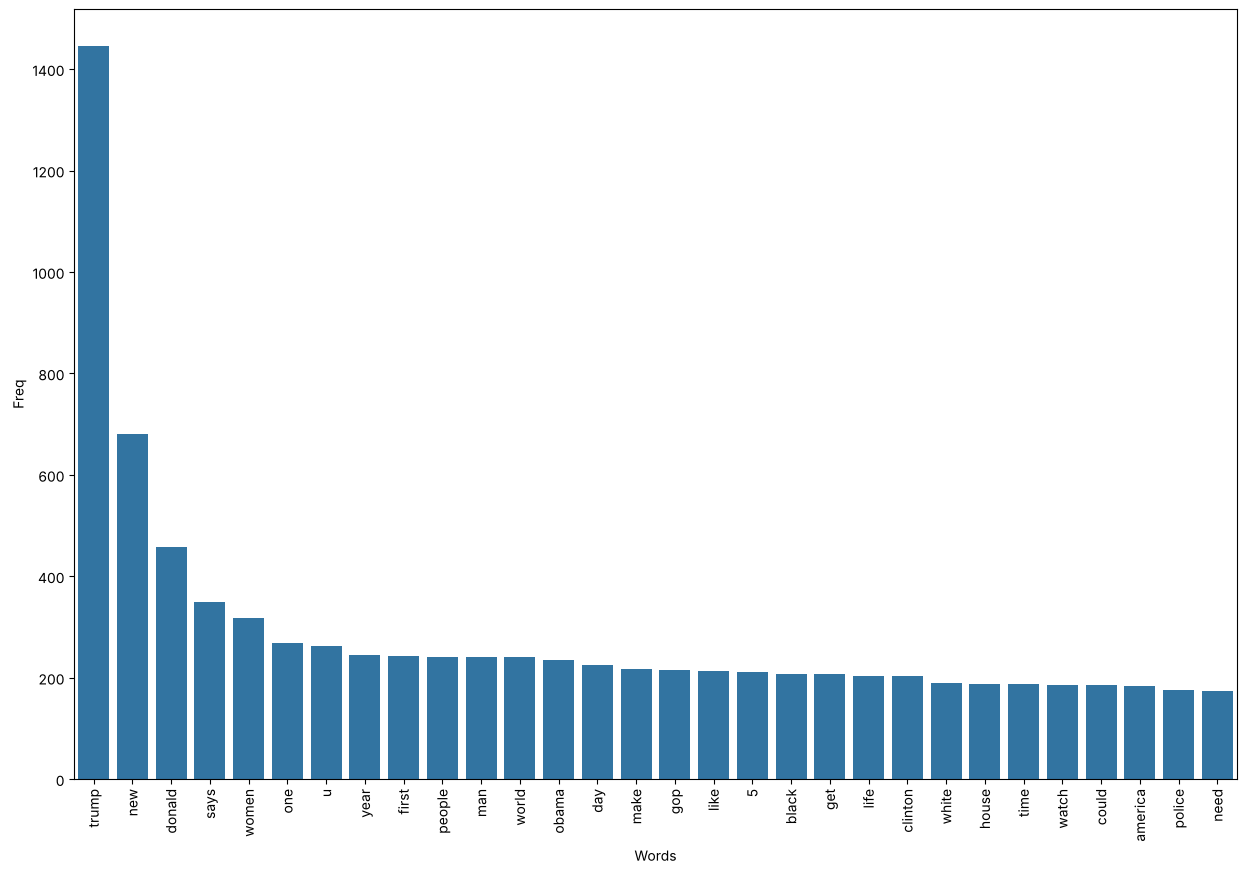

In [54]:
plt.figure(figsize = (15,10))
plot = sns.barplot(x = df_no_sarcasmo.iloc[:30].Words, y =df_no_sarcasmo.iloc[:30].Freq)
for f in plot.get_xticklabels():
  f.set_rotation(90)

plt.show()

# Analisis de df-sarcastico

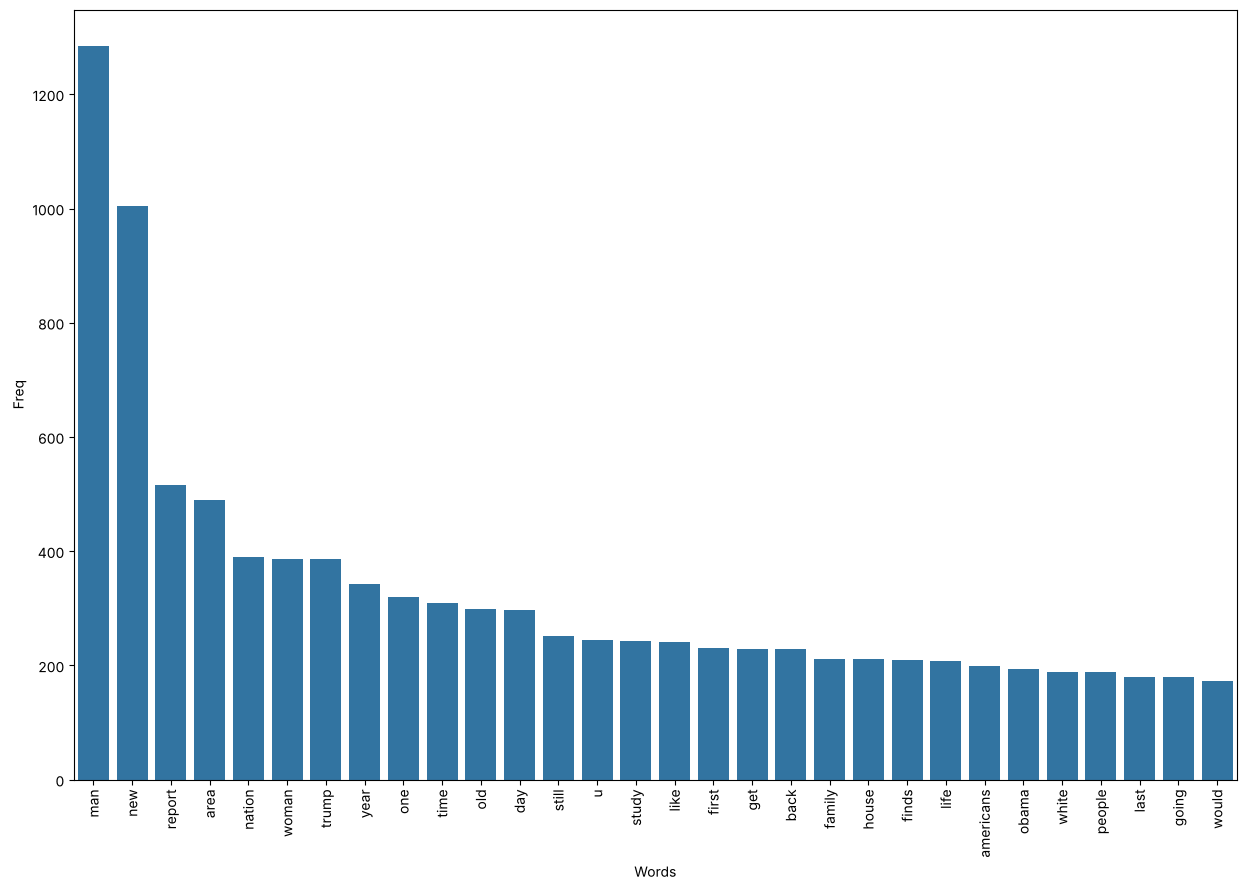

In [55]:
df_sarcasmo = df[df.is_sarcastic == 1]
todos_titulares_sarcasmo = []

for i in range(df_sarcasmo.shape[0]):
  titular = df_sarcasmo.iloc[i].headline
  titular = nltk.tokenize.RegexpTokenizer('[\w]+').tokenize(titular)
  titular = [word for word in titular if word not in stopwords]

  todos_titulares_sarcasmo.append(titular)

todos_titulares_sarcasmo = list(itertools.chain(*todos_titulares_sarcasmo))

freq_sarcasmo = nltk.FreqDist(todos_titulares_sarcasmo)
df_sarcasmo = pd.DataFrame(list(freq_sarcasmo.items()), columns = ['Words', 'Freq'])
df_sarcasmo.sort_values('Freq', ascending = False, inplace = True)
df_sarcasmo = df_sarcasmo.reset_index()

plt.figure(figsize = (15,10))
plot = sns.barplot(x = df_sarcasmo.iloc[:30].Words, y = df_sarcasmo.iloc[:30].Freq)
for f in plot.get_xticklabels():
  f.set_rotation(90)

plt.show()

# Stemming

In [56]:
dataset = df

In [57]:
dataset = pd.concat([dataset.headline, dataset.is_sarcastic], axis = 1)

In [58]:
dataset

,headline,is_sarcastic
0,thirtysomething scientists unveil doomsday clo...,1
1,dem rep. totally nails why congress is falling...,0
2,eat your veggies: 9 deliciously different recipes,0
3,inclement weather prevents liar from getting t...,1
4,mother comes pretty close to using word 'strea...,1
...,...,...
28614,jews to celebrate rosh hashasha or something,1
28615,internal affairs investigator disappointed con...,1
28616,the most beautiful acceptance speech this week...,0
28617,mars probe destroyed by orbiting spielberg-gat...,1


In [59]:
import re
from nltk.stem import PorterStemmer

In [60]:
titular_list = []
for titular in dataset.headline:
  titular = re.sub("[^a-zA-Z]", " ", str(titular))
  titular = titular.lower()
  titular = nltk.word_tokenize(titular)
  titular = [palabra for palabra in titular if len(palabra) >= 3]
  titular = [palabra for palabra in titular if not palabra in stopwords]
  titular = " ".join(titular)
  titular_list.append(titular)

In [61]:
titular_list[:10]

['thirtysomething scientists unveil doomsday clock hair loss',
 'dem rep totally nails congress falling short gender racial equality',
 'eat veggies deliciously different recipes',
 'inclement weather prevents liar getting work',
 'mother comes pretty close using word streaming correctly',
 'white inheritance',
 'ways file taxes less stress',
 'richard branson global warming donation nearly much cost failed balloon trips',
 'shadow government getting large meet marriott conference room',
 'lots parents know scenario']

In [62]:
dataset['titular_limpio'] = titular_list

# Stemming: recortamos cada palabra a su raíz
stemmer = PorterStemmer()
dataset['titular_stem'] = [' '.join(stemmer.stem(p) for p in t.split()) for t in titular_list]
dataset[['titular_limpio', 'titular_stem']].head()

,titular_limpio,titular_stem
0,thirtysomething scientists unveil doomsday clo...,thirtysometh scientist unveil doomsday clock h...
1,dem rep totally nails congress falling short g...,dem rep total nail congress fall short gender ...
2,eat veggies deliciously different recipes,eat veggi delici differ recip
3,inclement weather prevents liar getting work,inclement weather prevent liar get work
4,mother comes pretty close using word streaming...,mother come pretti close use word stream corre...


In [63]:
dataset

,headline,is_sarcastic,titular_limpio,titular_stem
0,thirtysomething scientists unveil doomsday clo...,1,thirtysomething scientists unveil doomsday clo...,thirtysometh scientist unveil doomsday clock h...
1,dem rep. totally nails why congress is falling...,0,dem rep totally nails congress falling short g...,dem rep total nail congress fall short gender ...
2,eat your veggies: 9 deliciously different recipes,0,eat veggies deliciously different recipes,eat veggi delici differ recip
3,inclement weather prevents liar from getting t...,1,inclement weather prevents liar getting work,inclement weather prevent liar get work
4,mother comes pretty close to using word 'strea...,1,mother comes pretty close using word streaming...,mother come pretti close use word stream corre...
...,...,...,...,...
28614,jews to celebrate rosh hashasha or something,1,jews celebrate rosh hashasha something,jew celebr rosh hashasha someth
28615,internal affairs investigator disappointed con...,1,internal affairs investigator disappointed con...,intern affair investig disappoint conspiraci w...
28616,the most beautiful acceptance speech this week...,0,beautiful acceptance speech week came queer ko...,beauti accept speech week came queer korean
28617,mars probe destroyed by orbiting spielberg-gat...,1,mars probe destroyed orbiting spielberg gates ...,mar probe destroy orbit spielberg gate space p...


In [64]:
dataset_stem = pd.concat([dataset.titular_stem, dataset.is_sarcastic], axis = 1)

In [65]:
dataset_stem

,titular_stem,is_sarcastic
0,thirtysometh scientist unveil doomsday clock h...,1
1,dem rep total nail congress fall short gender ...,0
2,eat veggi delici differ recip,0
3,inclement weather prevent liar get work,1
4,mother come pretti close use word stream corre...,1
...,...,...
28614,jew celebr rosh hashasha someth,1
28615,intern affair investig disappoint conspiraci w...,1
28616,beauti accept speech week came queer korean,0
28617,mar probe destroy orbit spielberg gate space p...,1


# Lemmatizar

In [66]:
from nltk.stem import WordNetLemmatizer

In [67]:
word_lem = WordNetLemmatizer()

In [68]:
frase = dataset_stem.titular_stem[40]

In [69]:
frase

'best cloth man child life'

In [70]:
nltk.download('wordnet')

In [71]:
word_lem.lemmatize(frase)

'best cloth man child life'

In [72]:
nltk.download('averaged_perceptron_tagger')

In [73]:
from nltk.corpus import wordnet

In [74]:
def get_wordnet_pos(word):
    """Map POS tag to first character lemmatize() accepts"""
    tag = nltk.pos_tag([word])[0][1][0].upper() #esto nos devuelve algo, queremos usar el de la posicion 0 y 1
    # word, posicion, number, lemma. 0, 1 y 0.
    tag_dict = {"J": wordnet.ADJ,
                "N": wordnet.NOUN,
                "V": wordnet.VERB,
                "R": wordnet.ADV}

    return tag_dict.get(tag, wordnet.NOUN)

In [75]:
from nltk.stem import WordNetLemmatizer
wordnet_lemmatizer = WordNetLemmatizer()

In [76]:
nltk.download('averaged_perceptron_tagger_eng')

In [77]:
lista_frases_tok_lem = []
for titular in dataset.titular_limpio:
  titular_tok = nltk.word_tokenize(titular)
  frase_lemma = [wordnet_lemmatizer.lemmatize(w, get_wordnet_pos(w)) for w in titular_tok] # así aparece en la documentación de WordNet
  frase_lemma = ' '.join(frase_lemma)
  lista_frases_tok_lem.append(frase_lemma)

In [78]:
dataset['titular_lemm'] = lista_frases_tok_lem
dataset[['titular_limpio', 'titular_lemm']].head()

,titular_limpio,titular_lemm
0,thirtysomething scientists unveil doomsday clo...,thirtysomething scientist unveil doomsday cloc...
1,dem rep totally nails congress falling short g...,dem rep totally nail congress fall short gende...
2,eat veggies deliciously different recipes,eat veggie deliciously different recipe
3,inclement weather prevents liar getting work,inclement weather prevents liar get work
4,mother comes pretty close using word streaming...,mother come pretty close use word stream corre...


In [79]:
dataset_lemm = pd.concat([dataset.titular_lemm,dataset.is_sarcastic],axis=1)
dataset_lemm.dropna(axis=0,inplace=True)  # Por si quedaron titulares vacios
dataset_lemm.head()

,titular_lemm,is_sarcastic
0,thirtysomething scientist unveil doomsday cloc...,1
1,dem rep totally nail congress fall short gende...,0
2,eat veggie deliciously different recipe,0
3,inclement weather prevents liar get work,1
4,mother come pretty close use word stream corre...,1


In [80]:
lista_titulos = list(dataset_lemm['titular_lemm'].values)

In [81]:
is_sarcas = dataset_lemm['is_sarcastic'].values

In [82]:
lista_titulos[:10]

['thirtysomething scientist unveil doomsday clock hair loss',
 'dem rep totally nail congress fall short gender racial equality',
 'eat veggie deliciously different recipe',
 'inclement weather prevents liar get work',
 'mother come pretty close use word stream correctly',
 'white inheritance',
 'way file tax less stress',
 'richard branson global warm donation nearly much cost fail balloon trip',
 'shadow government get large meet marriott conference room',
 'lot parent know scenario']

# Vectorizamos

In [83]:
from sklearn.feature_extraction.text import CountVectorizer

In [84]:
max_features = 1000

In [85]:
coun_vec = CountVectorizer(max_features = max_features)

In [86]:
matriz_titulos = coun_vec.fit_transform(lista_titulos)

In [87]:
all_words = coun_vec.get_feature_names_out()

In [88]:
all_words

array(['abortion', 'abuse', 'accidentally', 'accuse', 'across', 'act',
       'action', 'activist', 'actor', 'actually', 'add', 'address',
       'administration', 'admits', 'adorable', 'advice', 'age', 'agent',
       'ahead', 'aid', 'air', 'airline', 'airport', 'album', 'allegation',
       'allow', 'almost', 'already', 'always', 'amaze', 'amazon',
       'america', 'american', 'animal', 'anniversary', 'announce',
       'announces', 'another', 'answer', 'anti', 'anyone', 'anything',
       'apartment', 'apologizes', 'apparently', 'apple', 'area', 'arm',
       'around', 'arrest', 'art', 'artist', 'ask', 'asks', 'assault',
       'attack', 'attempt', 'audience', 'avoid', 'award', 'away', 'baby',
       'back', 'bad', 'bag', 'ball', 'ban', 'band', 'bank', 'bar', 'base',
       'bathroom', 'battle', 'bear', 'beat', 'beautiful', 'beauty',
       'become', 'begin', 'behind', 'believe', 'ben', 'bernie', 'best',
       'biden', 'big', 'bill', 'billion', 'bird', 'birth', 'birthday',
       

# Modelo

In [89]:
X = matriz_titulos.toarray()
y = is_sarcas

In [90]:
from sklearn.model_selection import train_test_split

In [91]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 0, stratify = y) # stratify balancea

In [92]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix

## Tarea: buscar un modelo mejor
Primero el Random Forest visto en clase y después dos modelos más que suelen funcionar bien con texto.

In [93]:
rf = RandomForestClassifier(n_estimators = 50, random_state=42) # mejorar modelo
rf.fit(X_train, y_train)
print("accuracy: ", rf.score(X_test, y_test))

accuracy:  0.7117400419287212


In [94]:
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB

modelos = {
    'Random Forest': rf,
    'Regresión logística': LogisticRegression(max_iter = 1000),
    'Naive Bayes': MultinomialNB(),
}
for nombre, m in modelos.items():
    if nombre != 'Random Forest':
        m.fit(X_train, y_train)
    print(f'{nombre:22} accuracy: {m.score(X_test, y_test):.3f}')

Random Forest          accuracy: 0.712


Regresión logística    accuracy: 0.730
Naive Bayes            accuracy: 0.718


## Conclusiones
- Las palabras más frecuentes cambian según el tipo de titular. En los sarcásticos (de *The Onion*) aparecen *man, new, report, area, nation*: el estilo de las noticias falsas del tipo "Area man…". En los no sarcásticos (de *HuffPost*) dominan *trump, new, donald, says, women*.
- El *stemming* recorta cada palabra a una raíz que puede no ser una palabra real; la *lematización* la lleva a su forma de diccionario. En la versión de clase, la columna lematizada recibía el texto sin lematizar y el stemmer no se aplicaba: se corrigieron las dos cosas.
- Comparando modelos: regresión logística 73,0%, Naive Bayes 71,8% y Random Forest 71,2%. Los modelos lineales suelen funcionar bien con texto representado como bolsa de palabras.
- Mejoras posibles: usar TF-IDF en lugar de conteos, aumentar `max_features` o incluir pares de palabras (bigramas).